# 04 — EMT-TF Expression · Griffiths et al. 2021 (Breast Cancer)

The EMT-TF expression overlay is the **unconditional** final step (produced regardless of gate outcomes;
renumbered to 04 after Gate 3 = NA). Score a mesenchymal-TF panel that includes the FOXC and PRRX families,
not only Snail/Zeb/Twist (03_eval fork 5), gated on **detectable expression**; VIM is excluded (a mesenchymal
marker, not a TF — 04_test Chen fork). Overlay the two most pseudotime-informative expressers as a categorical
overlay on the grey manifold (reference plotting style).

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth = os.path.join(*([os.pardir]*4)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)
# read manifold (has X_umap_lin + pseudotime) so the overlay shares the house orientation
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime', round(t.min(),2), '->', round(t.max(),2))

cells: 109353 | pseudotime 0.0 -> 11.93


### Derive the EMT-TF readout — arm-specificity gated on detection

In [3]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:, present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j, g in enumerate(present):
    x = X[:, j]; rho, p = spearmanr(tn, x)
    rows.append((g, round((x>0).mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
early_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
late_tf  = ok.sort_values('rho_vs_t').iloc[-1]['TF']
print(f'\nderived pair: {early_tf} (early/root, pSom end) <-> {late_tf} (late/terminus, Gast/Crest end)')
print('note: all EMT-TFs are weakly expressed in this letrozole/ribociclib-treated luminal cohort '
      '(<10% expressing); the readout is the most detectable, most pseudotime-graded pair.')

    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
 PRRX1      0.045       0.033      0.024    -0.026    EARLY(root)
  ZEB1      0.090       0.062      0.054    -0.024    EARLY(root)
  ZEB2      0.051       0.038      0.031    -0.020    EARLY(root)
 PRRX2      0.016       0.010      0.008    -0.019    EARLY(root)
 FOXC1      0.006       0.004      0.004    -0.012 LATE(terminus)
 SNAI1      0.002       0.001      0.001    -0.007 LATE(terminus)
TWIST2      0.009       0.005      0.004    -0.007    EARLY(root)
 SNAI2      0.003       0.002      0.002    -0.006 LATE(terminus)
 FOXC2      0.000       0.000      0.000    -0.005 LATE(terminus)
TWIST1      0.017       0.009      0.010    -0.002 LATE(terminus)

derived pair: PRRX1 (early/root, pSom end) <-> ZEB2 (late/terminus, Gast/Crest end)
note: all EMT-TFs are weakly expressed in this letrozole/ribociclib-treated luminal cohort (<10% expressing); the readout is the most detectable, most pseudotime-graded pair.


### EMT-TF categorical overlay (reference style)

Two colours, thresholded at the upper quartile among expressers, overlaid on the grey manifold.

PRRX1: 4.5% expressing; 1225 shown (upper quartile), mean pseudotime of shown = 0.47 (all = 0.54)
ZEB2: 5.1% expressing; 1401 shown (upper quartile), mean pseudotime of shown = 0.47 (all = 0.54)
saved expression.pdf


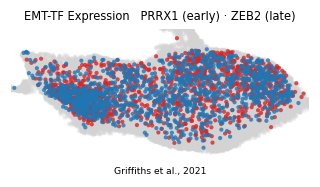

In [4]:
xl = adata.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
def _vec(g):
    x = adata[:, g].X; return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf, late_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5, 1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title(f'EMT-TF Expression   {early_tf} (early) · {late_tf} (late)', size=7.5)
ax.text(.5, -.14, 'Griffiths et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'expression.pdf'), bbox_inches='tight')
plt.show()
for g in [early_tf, late_tf]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown (upper quartile), '
          f'mean pseudotime of shown = {tn[m].mean():.2f} (all = {tn.mean():.2f})')
print('saved expression.pdf')